# Estimar resistencia en recetas de hormigón no vistas
### Unidades 2, 3 y 4 · Laboratorio de Datos I · UNTDF

**Parcial I2 · Ingeniería Industrial · Resolución individual domiciliaria · Plazo: dos semanas**

Se dispone de ensayos de mezclas de hormigón con diferentes composiciones y edades. Se explorará cómo se relacionan estas características con la resistencia y se comparará una regresión lineal con alternativas polinómicas regularizadas.

**Pregunta central:** ¿un modelo polinómico de grado 2 con Ridge reduce el error de estimación de la resistencia respecto de una regresión lineal en recetas que no fueron utilizadas para entrenar?

Nombre y apellido: … · Carrera: … · Fecha de entrega: …

## Guía de trabajo

- Resolver C1–C10 en este archivo; agregar celdas si fueran necesarias, conservando los títulos.
- Usar los CSV locales, con diccionario y particiones provistos. No se pide recolectar ensayos ni diseñar una mezcla.
- La cátedra entrega configuración inicial (setup) y carga. El análisis exploratorio de datos (EDA), la preparación, los modelos y la interpretación se resuelven en los espacios indicados.
- Comparar una referencia media, una regresión lineal y tres modelos de grado 2 con Ridge. No agregar otras variables, grados o algoritmos.
- Explorar sólo entrenamiento. Usar validación fija para comparar en C6 y seleccionar en C7. Abrir prueba recién en C8 y no reajustar el modelo con validación.
- Entregar un notebook ejecutado desde kernel limpio, con salidas, interpretaciones y carpeta `datasets/`. No se requiere informe separado.

La ejecución del esqueleto vacío sólo comprueba el soporte. Las etiquetas de prueba están incluidas; el orden de acceso es parte del procedimiento. La siguiente celda configura el entorno.

In [1]:
# Si hiciera falta, instalar previamente las dependencias de requirements.txt.
# === Setup de la cátedra — Laboratorio de Datos I (UNTDF) ===
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from importlib.metadata import version
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
rng = np.random.default_rng(SEED)

# Paleta de la cátedra (fondo claro) — usar por semántica, no por gusto
AZUL   = "#4A7A9B"  # serie base
CIAN   = "#5AA9D6"  # serie secundaria / estructura
DORADO = "#D8A24A"  # transición
AMBAR  = "#E89340"  # único acento: lo que sostiene la conclusión
GRIS   = "#B9C4CE"  # contexto / referencia
TINTA  = "#0E1620"  # texto, ejes y bordes
PROGRESION = [AZUL, CIAN, DORADO, AMBAR]

plt.rcParams.update({
    "figure.figsize": (11.5, 4),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRIS, "grid.alpha": 0.35,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": TINTA, "axes.labelcolor": TINTA, "axes.edgecolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA,
    "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[AZUL, AMBAR, CIAN, DORADO, GRIS]),
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

**Interpretación.** El entorno, la semilla y la paleta quedan disponibles. Las dependencias probadas se encuentran en `requirements.txt`; todas las importaciones se concentran en esta celda.

# 1. Distinguir composición, edad y resistencia
## 1.1 Contexto y glosario mínimo

El **hormigón** combina una pasta de cemento y agua con agregados finos y gruesos. No es sinónimo de cemento. La reacción del cemento con agua contribuye al endurecimiento; el **curado** comprende las condiciones de humedad y temperatura que acompañan ese desarrollo. La **edad** es el tiempo transcurrido hasta medir la resistencia, en días; no identifica por sí sola todas las condiciones de curado.

La tabla contiene siete cantidades de componentes en **kg por m³ de mezcla** y la edad del ensayo. Escoria y ceniza volante son materiales complementarios; el superplastificante es un aditivo que modifica la fluidez. Cero en alguno de estos componentes puede indicar ausencia válida. No sumar estas cantidades como si fueran porcentajes: son masas por volumen.

La **resistencia a compresión**, objetivo en **MPa**, representa la tensión medida en un ensayo de compresión. Para el parcial interesa estimar esa medición: un error de 5 MPa es una diferencia de resistencia, no un error del 5 %. Una receta identifica exactamente las siete cantidades de componentes; la misma receta puede medirse a distintas edades y producir resistencias distintas.

El conjunto se atribuye a I-Cheng Yeh y está publicado en UCI. No se requiere química avanzada ni conocimiento de normativa de diseño. Lecturas seleccionadas, con dedicación contextual de 2–3 horas: [ficha y unidades de UCI 165](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength) y [preguntas frecuentes de la American Cement Association](https://www.cement.org/cement-concrete/cement-concrete-faq/), limitadas a diferencia entre cemento y hormigón, resistencia a 28 días y factores que influyen en resistencia. El glosario anterior proporciona el vocabulario en español.

> 📌 **Concepto clave — Generalizar entre recetas.**
> La evaluación reserva composiciones completas. No se busca reconocer otra edad de una receta ya vista, sino estimar ensayos de composiciones ausentes del entrenamiento, dentro de la población representada por la fuente.

## 1.2 Diccionario de variables

| Columna | Significado / unidad | Papel |
|---|---|---|
| `cemento` | Cemento, kg/m³ | Predictor |
| `escoria` | Escoria de alto horno, kg/m³ | Predictor; cero válido |
| `ceniza_volante` | Ceniza volante, kg/m³ | Predictor; cero válido |
| `agua` | Agua, kg/m³ | Predictor |
| `superplastificante` | Aditivo superplastificante, kg/m³ | Predictor; cero válido |
| `agregado_grueso` | Agregado grueso, kg/m³ | Predictor |
| `agregado_fino` | Agregado fino, kg/m³ | Predictor |
| `edad_dias` | Edad en el momento del ensayo, días | Predictor |
| `resistencia_mpa` | Resistencia a compresión medida, MPa | Objetivo |
| `id_ensayo` | Número de fila del archivo original | Sólo trazabilidad; no ID de probeta certificado |
| `grupo_receta` | Código creado a partir de los siete componentes exactamente coincidentes | Sólo partición; nunca predictor |

Los nombres fueron traducidos y se agregaron identificadores; no se modificaron mediciones. Se conservan repeticiones del original porque no hay identificador de réplica que permita resolver su causa. Las composiciones similares pero no idénticas pueden quedar en grupos distintos: esta separación no establece independencia química ni de laboratorio.

Vocabulario del código: variable predictora (*feature*), variable objetivo (*target*), entrenamiento (*training*), validación (*validation*), prueba (*test*), ajuste (*fit*) y predicción (*predict*). `alpha` es un hiperparámetro (*hyperparameter*) de Ridge. Aprender transformaciones con datos reservados provoca filtración de información (*data leakage*).

## 1.3 Consigna C1 — Formular la estimación

Completar una tabla con unidad de observación, objetivo y unidad, ocho predictores, momento en que se conocen y población a la que se limita la estimación. Explicar la diferencia entre receta y ensayo. Indicar dos afirmaciones que este trabajo no permitiría sostener, incluyendo por qué un buen RMSE no certifica seguridad estructural.

## Respuesta C1 ##
**Unidad de observacion**: Un ensayo de resistencia a compresion realizado sobre una determinada receta de hormigon a una determinada edad

**objetivo y unidad**: El objetivo es estimar la resistencia del hormigon y su unidad de medida es MPPa

**Los ocho predictores**:
 Predictor | Qué representa? | Unidad |
|---|---|---|
| `cemento` | Cantidad de cemento | kg/m³ |
| `escoria` | Escoria de alto horno | kg/m³ |
| `ceniza_volante` | Cantidad ceniza volante | kg/m³ |
| `agua` | Cantidad de agua | kg/m³ | 
| `superplastificante` | Cantidad de aditivo superplastificante | kg/m³ |
| `agregado_grueso` | Cantidad de agregado grueso | kg/m³ |
| `agregado_fino` | Cantidad de agregado fino | kg/m³ |
| `edad_dias` | Edad en el momento del ensayo | días |

Los predictores **se conocen** antes de observar la resistencia, la composicion se define al preparar la mezcla y la ead del ensayo esta fijada antes de realizar la medicion

La poblacion **se limita** a mezclas de hormigon con composiciones y edades similares a las representadas en el conjunto de datos utilizado.

**Diferencia entre receta y ensayo**: La receta define la composicion: el ensayo es una observacion de esa receta bajo una determinada edad de medicion.

**Dos afirmaciones que no podriamos sostener**: No podemos afirmar que el modelo sea valido para cualquier hormigon, porque solo fue evaluado sobre la poblacion de esta dataset.
Un buen RMSE no certifica seguridad estructural, porque solo mide el error predictivo del modelo sobre resistencia a compresion dentro del conjunto evaluado, no tienen en cunta cargas, normativas o el factor de seguridad.



# 2. Reservar recetas completas para validar y probar
## 2.1 Protocolo de separación

Se conservan los 1.030 registros y las 428 recetas exactas. La cátedra separó aproximadamente 70/15/15 de las recetas en entrenamiento, validación y prueba, usando semilla 42. Como cada receta aporta una cantidad distinta de ensayos, los porcentajes de filas no tienen que coincidir exactamente.

| Bloques | Datos | Función |
|---|---|---|
| C3–C5 | Entrenamiento (`train.csv`) | Auditar, explorar y ajustar preparación |
| C6 | Entrenamiento y validación fija | Comparar alternativas |
| C7 | Resultados de validación | Congelar método y configuración |
| C8–C9 | Prueba reservada | Evaluar una vez y analizar errores |

Este caso utiliza **validación fija, sin validación cruzada (cross-validation)**. No se cambian las particiones. Las recetas se agruparon por los siete componentes, sin usar edad ni resistencia. La edad debe poder variar dentro de un grupo; el código de receta no entra en los modelos. Las filas idénticas conservadas quedan en el mismo conjunto.

## 2.2 Cargar entrenamiento y validación

El soporte lee estas dos tablas y comprueba que no compartan recetas. La prueba no se carga ni se resume todavía. Los controles de calidad solicitados en C3 deben implementarse aparte.

In [2]:
RUTA_DATOS = Path("datasets")
COMPONENTES = ["cemento","escoria","ceniza_volante","agua","superplastificante","agregado_grueso","agregado_fino"]
PREDICTORES = COMPONENTES + ["edad_dias"]
OBJETIVO = "resistencia_mpa"
PROHIBIDAS = ["id_ensayo","grupo_receta",OBJETIVO]
entrenamiento = pd.read_csv(RUTA_DATOS / "train.csv")
validacion = pd.read_csv(RUTA_DATOS / "validacion.csv")
assert set(entrenamiento.grupo_receta).isdisjoint(set(validacion.grupo_receta))
display(pd.DataFrame({"conjunto":["entrenamiento","validacion"],
                      "ensayos":[len(entrenamiento),len(validacion)],
                      "recetas":[entrenamiento.grupo_receta.nunique(),validacion.grupo_receta.nunique()]}))

,conjunto,ensayos,recetas
0,entrenamiento,729,299
1,validacion,148,64


**Interpretación.** Entrenamiento y validación están disponibles con sus recetas completas. Cada fila sigue siendo un ensayo: agrupar para separar no significa promediar edades ni resistencias.

## 2.3 Consigna C2 — Explicar la separación y las exclusiones

Describir qué podría ocurrir al repartir al azar ensayos de una misma receta entre entrenamiento y prueba. Explicar por qué ni los identificadores ni la resistencia deben entrar en `X`, y por qué usar resistencia para formar grupos invalidaría el criterio actual. Indicar una dependencia que el agrupamiento por composición exacta no elimina.

## Respuesra C2 ##
**Respuesta.** si los ensayos de una misma receta se repartieran al azar entre entranamiento y prueba, el modelo podria encontrarse en prueba con una composicion que ya vio durante le entrenamiento, aunque corresponda a otra edad. Eso hara que la evaluacion no mida realmente la capacidad de generalizar a recetas nuevas.

En este caso tenemos dos tipos de identificadores "id_ensayo" que no debe entrar en x por que es un numero para saber que fila del archivo corresponde a cada registro y no representa una caracteristica fisica de la mezcla. Por la misma razon el identificador "grupo_recetas" tampoco debe usarse como predctor porque sirve para reconocer que ensayos pertenecen a la misma receta, y la resistencia tampoco puede entarar en x por que es la variable objetivo que se quiere estimar, incluirla produciria fuga de informacion.

la resistencia tampoco debe utilizarse para formar los grupos, porque una misma receta puede presentar distintas resistencias segun la edad del ensayo, si se agrupara, pasaria que ensayos de una misma composicion podrian quedar repetida entre entrenamiento y prueba y se perderia el criterio de reservar recetas completas.

Por ultimo, agrupar por composicion exacta no eliminaria todas las dependencias, ya que recetas muy parecidas pero no indenticas pueden quedar en grupos distintos. aunque las mezclas puedan comportarse de forma parecida.

# 3. Auditar unidades, ceros y repeticiones
## 3.1 Consigna C3 — Documentar hallazgos reales

En entrenamiento: presentar tipos y nulos; contar identificadores repetidos y filas repetidas considerando los ocho predictores más objetivo; revisar rangos y ceros por componente, edades positivas y resistencia positiva. Comprobar que las siete cantidades sean constantes dentro de cada receta y contar edades distintas por receta.

Entregar una tabla con control, cantidad y decisión. **Conservar todos los registros y los ceros válidos**, conforme al contrato. Distinguir una repetición de mediciones de una repetición del identificador; sin datos de réplicas no se puede atribuir una causa. No borrar valores extremos automáticamente ni introducir faltantes artificiales.

In [3]:
# Espacio de resolución — C3 · auditoría
# C3 - Auditoría del conjunto de entrenamiento

# 1. Tipos de datos y valores nulos
print("TIPOS DE DATOS")
print(entrenamiento.dtypes)

print("\nVALORES NULOS")
print(entrenamiento.isna().sum())


# 2. Identificadores repetidos
ids_repetidos = entrenamiento["id_ensayo"].duplicated().sum()


# 3. Filas repetidas considerando los 8 predictores + objetivo
columnas_revision = PREDICTORES + [OBJETIVO]

filas_repetidas = entrenamiento.duplicated(
    subset=columnas_revision
).sum()


# 4. Rangos mínimos y máximos
print("\nRANGOS")
rangos = (
    entrenamiento[PREDICTORES + [OBJETIVO]]
    .agg(["min", "max"])
    .T
)

display(rangos)


# 5. Ceros por componente
ceros_componentes = pd.DataFrame({
    "componente": COMPONENTES,
    "cantidad_ceros": [
        (entrenamiento[col] == 0).sum()
        for col in COMPONENTES
    ]
})

print("\nCEROS POR COMPONENTE")
display(ceros_componentes)


# 6. Edad y resistencia positivas
edades_no_positivas = (
    entrenamiento["edad_dias"] <= 0
).sum()

resistencias_no_positivas = (
    entrenamiento["resistencia_mpa"] <= 0
).sum()


# 7. Constancia de los componentes dentro de cada receta
constancia = (
    entrenamiento
    .groupby("grupo_receta")[COMPONENTES]
    .nunique()
)

recetas_inconsistentes = (constancia > 1).any(axis=1).sum()


# 8. Edades distintas por receta
edades_por_receta = (
    entrenamiento
    .groupby("grupo_receta")["edad_dias"]
    .nunique()
)

print("\nEDADES DISTINTAS POR RECETA")
print(edades_por_receta.describe())


# 9. Tabla resumen de controles
tabla_controles = pd.DataFrame({
    "control": [
        "Valores nulos",
        "ID de ensayo repetidos",
        "Filas repetidas",
        "Edades no positivas",
        "Resistencias no positivas",
        "Recetas con componentes no constantes",
    ],
    "cantidad": [
        entrenamiento.isna().sum().sum(),
        ids_repetidos,
        filas_repetidas,
        edades_no_positivas,
        resistencias_no_positivas,
        recetas_inconsistentes,
    ],
    "decision": [
        "No requiere acción si es 0",
        "Conservar si es 0; revisar si hay repetidos",
        "Conservar",
        "Revisar si aparece algún caso",
        "Revisar si aparece algún caso",
        "Debe ser 0; si no, revisar agrupamiento",
    ]
})

print("\nRESUMEN DE CONTROLES")
display(tabla_controles)

ensayos_por_receta = (
    entrenamiento
    .groupby("grupo_receta")
    .size()
    .reset_index(name="cantidad_ensayos")
    .sort_values("cantidad_ensayos", ascending=False)
)

display(ensayos_por_receta)

print(
    "Promedio de ensayos por receta:",
    ensayos_por_receta["cantidad_ensayos"].mean()
)

print(
    "Mínimo de ensayos por receta:",
    ensayos_por_receta["cantidad_ensayos"].min()
)

print(
    "Máximo de ensayos por receta:",
    ensayos_por_receta["cantidad_ensayos"].max()
)


columnas_revision = PREDICTORES + [OBJETIVO]

repetidas = entrenamiento[
    entrenamiento.duplicated(
        subset=columnas_revision,
        keep=False
    )
].sort_values(columnas_revision)

display(
    repetidas[
        ["id_ensayo", "grupo_receta"] + columnas_revision
    ]
)

print("Filas involucradas en repeticiones:", len(repetidas))
grupos_repetidos = (
    repetidas
    .groupby(columnas_revision)
    .size()
    .reset_index(name="cantidad")
    .sort_values("cantidad", ascending=False)
)

display(grupos_repetidos)

TIPOS DE DATOS
id_ensayo               int64
cemento               float64
escoria               float64
ceniza_volante        float64
agua                  float64
superplastificante    float64
agregado_grueso       float64
agregado_fino         float64
edad_dias               int64
resistencia_mpa       float64
grupo_receta            int64
dtype: object

VALORES NULOS
id_ensayo             0
cemento               0
escoria               0
ceniza_volante        0
agua                  0
superplastificante    0
agregado_grueso       0
agregado_fino         0
edad_dias             0
resistencia_mpa       0
grupo_receta          0
dtype: int64

RANGOS


,min,max
cemento,108.300000,540.000000
escoria,0.000000,359.400000
ceniza_volante,0.000000,200.000000
agua,121.750000,246.900000
superplastificante,0.000000,32.200000
agregado_grueso,801.000000,1145.000000
agregado_fino,594.000000,992.600000
edad_dias,1.000000,365.000000
resistencia_mpa,2.331808,81.751169



CEROS POR COMPONENTE


,componente,cantidad_ceros
0,cemento,0
1,escoria,331
2,ceniza_volante,423
3,agua,0
4,superplastificante,286
5,agregado_grueso,0
6,agregado_fino,0



EDADES DISTINTAS POR RECETA
count    299.000000
mean       2.324415
std        1.735469
min        1.000000
25%        1.000000
50%        1.000000
75%        4.000000
max        7.000000
Name: edad_dias, dtype: float64

RESUMEN DE CONTROLES


...

,grupo_receta,cantidad_ensayos
253,357,20
277,394,15
252,356,8
281,400,8
298,428,7
...,...,...
37,65,1
172,253,1
173,254,1
36,63,1


Promedio de ensayos por receta: 2.4381270903010033
Mínimo de ensayos por receta: 1
Máximo de ensayos por receta: 20


,id_ensayo,grupo_receta,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa
568,802,201,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
574,810,201,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
50,84,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
51,87,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
53,89,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
54,92,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
66,107,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
67,110,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
69,112,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
82,130,357,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


Filas involucradas en repeticiones: 36


,cemento,escoria,ceniza_volante,agua,superplastificante,agregado_grueso,agregado_fino,edad_dias,resistencia_mpa,cantidad
1,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171,4
3,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713,4
4,362.6,189.0,0.0,164.9,11.6,944.7,755.8,56,77.297154,4
5,362.6,189.0,0.0,164.9,11.6,944.7,755.8,91,79.296635,4
2,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819,3
6,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.398217,3
7,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.201007,3
8,425.0,106.3,0.0,153.5,16.5,852.1,887.1,28,60.294676,3
9,425.0,106.3,0.0,153.5,16.5,852.1,887.1,56,64.300532,3
10,425.0,106.3,0.0,153.5,16.5,852.1,887.1,91,65.196851,3


**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

En la salida tenemos tipos de datos donde nos separa que informacion es conformada por numeros **enteros** = int64 y por numeros **decimales** = float64
tambien confirmamos que no hay valores nulos en ninguna columna, o sea que no se detectaron valores faltantes en el conjunto de entrenamiento, tampoco identificadores repetidos, las edades y resistencia son positivas. Se detectaron 25 filas repetidas en total 36 filas, en el ultimo cuadro podemos ver que filas estan involucradas y la cantidad de veces que se repite (tienen misma composicion, misma edad y misma resistencia), que conservamos por que no podemos determinar si es un error o repeticiones validas, aunque puede dar mayor peso a ciertos casos durante el ajuse, por lo que puede ser una limitacion.

Los ceros de la escoria, ceniza volante y superplastificantes son validos, ya que,los siete componentes permanecen constantes dentro de cada receta, lo que confirma la coherencia del agrupamiento. Las recetas presentan entre 1 y 7 edades distintas de ensayo, con un promedio aproximado de 2,3 edades por receta.

# 4. Relacionar composición, edad y resistencia
## 4.1 Consigna C4 — Tres figuras y una tabla de entrenamiento

1. Histograma de resistencia con media señalada: describir centro, dispersión y asimetría.
2. Dispersión edad–resistencia: usar escala logarítmica sólo en el eje de edad si facilita la lectura, y justificar la elección. Diferenciar tendencia agregada de evolución de una receta particular.
3. Elegir cemento o agua y representar su relación con resistencia; distinguir edades hasta 28 días y mayores de 28 días mediante color o paneles. Justificar la variable elegida y explicar por qué la figura no identifica un efecto causal.

Agregar una tabla con mínimo, mediana, máximo y cantidad de ceros de los ocho predictores. Explicar dos decisiones de preparación o modelado que motive la evidencia. No usar validación ni prueba para estas figuras.

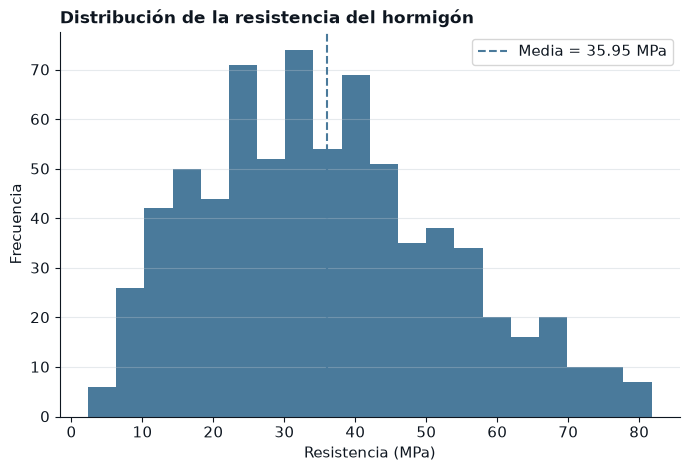

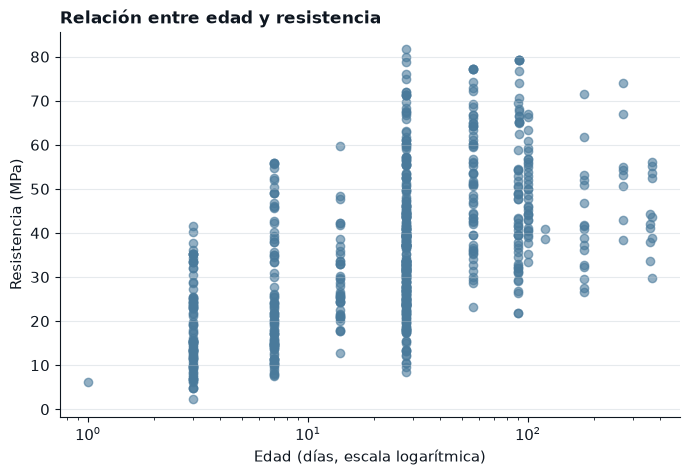

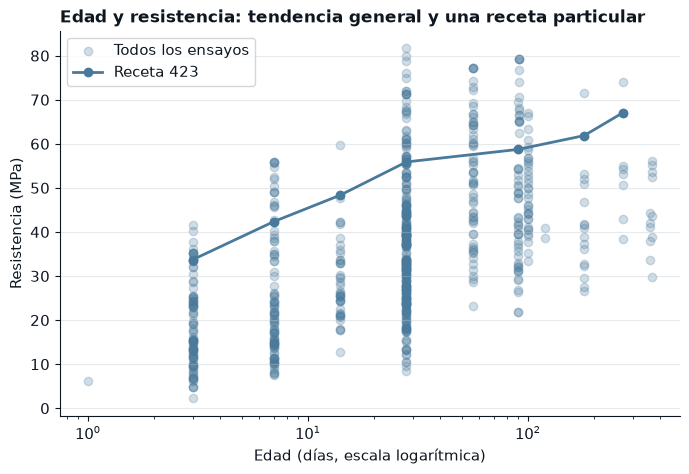

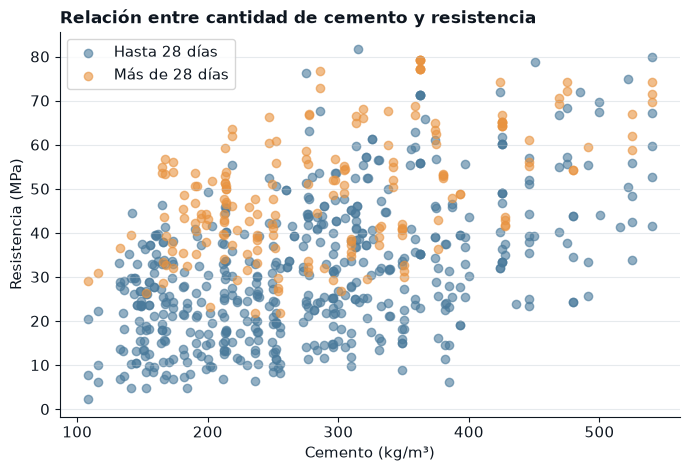

,mínimo,mediana,máximo,cantidad_ceros
cemento,108.30,277.00,540.0,0
escoria,0.00,24.00,359.4,331
ceniza_volante,0.00,0.00,200.0,423
agua,121.75,185.00,246.9,0
superplastificante,0.00,6.00,32.2,286
agregado_grueso,801.00,970.00,1145.0,0
agregado_fino,594.00,779.32,992.6,0
edad_dias,1.00,28.00,365.0,0


In [4]:
# Espacio de resolución — C4 · EDA
import matplotlib.pyplot as plt

media_resistencia = entrenamiento["resistencia_mpa"].mean()

plt.figure(figsize=(8, 5))

plt.hist(
    entrenamiento["resistencia_mpa"],
    bins=20
)

plt.axvline(
    media_resistencia,
    linestyle="--",
    label=f"Media = {media_resistencia:.2f} MPa"
)

plt.xlabel("Resistencia (MPa)")
plt.ylabel("Frecuencia")
plt.title("Distribución de la resistencia del hormigón")
plt.legend()


plt.figure(figsize=(8, 5))

plt.scatter(
    entrenamiento["edad_dias"],
    entrenamiento["resistencia_mpa"],
    alpha=0.6
)

plt.xscale("log")

plt.xlabel("Edad (días, escala logarítmica)")
plt.ylabel("Resistencia (MPa)")
plt.title("Relación entre edad y resistencia")

plt.show()

grupo_ejemplo = edades_por_receta.idxmax()

receta_ejemplo = (
    entrenamiento[
        entrenamiento["grupo_receta"] == grupo_ejemplo
    ]
    .sort_values("edad_dias")
)

plt.figure(figsize=(8, 5))

# Todos los ensayos
plt.scatter(
    entrenamiento["edad_dias"],
    entrenamiento["resistencia_mpa"],
    alpha=0.25,
    label="Todos los ensayos"
)

# Una receta particular
plt.plot(
    receta_ejemplo["edad_dias"],
    receta_ejemplo["resistencia_mpa"],
    marker="o",
    linewidth=2,
    label=f"Receta {grupo_ejemplo}"
)

plt.xscale("log")

plt.xlabel("Edad (días, escala logarítmica)")
plt.ylabel("Resistencia (MPa)")
plt.title("Edad y resistencia: tendencia general y una receta particular")
plt.legend()

plt.show()

#Relacion entre cemento y resistencia
entrenamiento["grupo_edad"] = entrenamiento["edad_dias"].apply(
    lambda x: "Hasta 28 días" if x <= 28 else "Más de 28 días"
)
plt.figure(figsize=(8, 5))

grupo_hasta_28 = entrenamiento[entrenamiento["edad_dias"] <= 28]
grupo_mas_28 = entrenamiento[entrenamiento["edad_dias"] > 28]

plt.scatter(
    grupo_hasta_28["cemento"],
    grupo_hasta_28["resistencia_mpa"],
    alpha=0.6,
    label="Hasta 28 días"
)

plt.scatter(
    grupo_mas_28["cemento"],
    grupo_mas_28["resistencia_mpa"],
    alpha=0.6,
    label="Más de 28 días"
)

plt.xlabel("Cemento (kg/m³)")
plt.ylabel("Resistencia (MPa)")
plt.title("Relación entre cantidad de cemento y resistencia")
plt.legend()

plt.show()

#tabla
tabla_predictores = pd.DataFrame({
    "mínimo": entrenamiento[PREDICTORES].min(),
    "mediana": entrenamiento[PREDICTORES].median(),
    "máximo": entrenamiento[PREDICTORES].max(),
    "cantidad_ceros": [
        (entrenamiento[col] == 0).sum()
        for col in PREDICTORES
    ]
})

display(tabla_predictores)


**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

**Histograma de distribucion de la resitencia del hormigon**:La media es 35,95 MPa, marcada con la línea punteada. La mayor concentración de valores parece estar aproximadamente entre 20 y 50 MPa, con el pico alrededor de los 30–35 MPa.
Sobre la dispersión, se ve que hay bastante amplitud: los valores van aproximadamente desde 2 MPa hasta 82 MPa, así que la resistencia no está concentrada en un rango muy estrecho.
Y sobre la asimetría, la distribución parece tener una leve asimetría hacia la derecha: después de los valores centrales, la frecuencia va disminuyendo gradualmente hacia resistencias más altas, formando una cola más larga hacia 60–80 MPa.

**Relacion entre edad y resistencia**: Se utilizó una escala logarítmica en el eje de edad porque las edades abarcan desde 1 hasta 365 días y, en escala lineal, los valores pequeños quedan muy concentrados. La escala logarítmica permite distinguir mejor las edades tempranas sin modificar los datos.

**Relacion entre cemento y resistencia**: Se eligió la cantidad de cemento porque es uno de los componentes principales de la mezcla y permite explorar su relación con la resistencia del hormigón.
Se observa una tendencia general de aumento de la resistencia a medida que aumenta la cantidad de cemento, aunque existe una dispersión importante. Los ensayos de más de 28 días tienden a presentar resistencias mayores que los de hasta 28 días. Sin embargo, no se afirmar un efecto causal del cemento sobre la resistencia, porque también varían simultáneamente otros componentes de la mezcla y la edad del ensayo.




# 5. Preparar ocho variables sin aprender de validación
## 5.1 Consigna C5 — Definir matrices y orden de transformación

Construir `X_ent`, `y_ent`, `X_val`, `y_val` con los ocho predictores permitidos. Comprobar que no haya identificadores ni objetivo en `X`. Documentar en una tabla qué se conserva, transforma o excluye.

Para la regresión lineal, usar `StandardScaler` seguido de `LinearRegression`. Para grado 2, usar **`PolynomialFeatures(degree=2, include_bias=False)` → `StandardScaler` → `Ridge`**. La expansión incluye términos originales, cuadrados e interacciones; luego se estandarizan todas las columnas expandidas. El orden es parte del contrato porque modifica la interpretación de la penalización.

Proveer únicamente el siguiente control de dimensiones, sin entrenar aún un modelo de resistencia: ajustar una expansión de grado 2 con entrenamiento e informar cuántas columnas produce. Explicar por qué los parámetros de escalado deben aprenderse sólo con entrenamiento. No transformar edad con logaritmo dentro del modelo: la escala logarítmica de C4 es sólo gráfica.

In [5]:
# Espacio de resolución
# C5 - Preparación de datos

from sklearn.preprocessing import PolynomialFeatures

# 1. Construir matrices de entrenamiento y validación
X_ent = entrenamiento[PREDICTORES].copy()
y_ent = entrenamiento[OBJETIVO].copy()

X_val = validacion[PREDICTORES].copy()
y_val = validacion[OBJETIVO].copy()

print("DIMENSIONES")
print("X_ent:", X_ent.shape)
print("y_ent:", y_ent.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


# 2. Comprobar que no haya identificadores ni objetivo dentro de X
columnas_prohibidas = ["id_ensayo", "grupo_receta", OBJETIVO]

prohibidas_ent = [
    col for col in columnas_prohibidas
    if col in X_ent.columns
]

prohibidas_val = [
    col for col in columnas_prohibidas
    if col in X_val.columns
]

print("\nCOLUMNAS PROHIBIDAS")
print("En X_ent:", prohibidas_ent)
print("En X_val:", prohibidas_val)


# 3. Tabla de decisiones sobre las variables
tabla_preparacion = pd.DataFrame({
    "variable": (
        PREDICTORES
        + ["id_ensayo", "grupo_receta", OBJETIVO]
    ),
    "decision": (
        ["Conservar como predictor"] * len(PREDICTORES)
        + ["Excluir", "Excluir", "Objetivo"]
    )
})

print("\nDECISIONES DE PREPARACIÓN")
display(tabla_preparacion)


# 4. Expansión polinómica de grado 2
# Se ajusta solamente con entrenamiento
polinomio = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_ent_poli = polinomio.fit_transform(X_ent)

# Validación solamente se transforma
X_val_poli = polinomio.transform(X_val)

print("\nEXPANSIÓN POLINÓMICA")
print(
    "Cantidad de predictores originales:",
    X_ent.shape[1]
)

print(
    "Cantidad de columnas después de grado 2:",
    X_ent_poli.shape[1]
)

print(
    "Dimensión de validación transformada:",
    X_val_poli.shape
)

DIMENSIONES
X_ent: (729, 8)
y_ent: (729,)
X_val: (148, 8)
y_val: (148,)

COLUMNAS PROHIBIDAS
En X_ent: []
En X_val: []

DECISIONES DE PREPARACIÓN


,variable,decision
0,cemento,Conservar como predictor
1,escoria,Conservar como predictor
2,ceniza_volante,Conservar como predictor
3,agua,Conservar como predictor
4,superplastificante,Conservar como predictor
5,agregado_grueso,Conservar como predictor
6,agregado_fino,Conservar como predictor
7,edad_dias,Conservar como predictor
8,id_ensayo,Excluir
9,grupo_receta,Excluir



EXPANSIÓN POLINÓMICA
Cantidad de predictores originales: 8
Cantidad de columnas después de grado 2: 44
Dimensión de validación transformada: (148, 44)


**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

Se construyeron las matrices de entrenamiento y validación utilizando únicamente los ocho predictores permitidos. Se excluyeron id_ensayo, grupo_receta y resistencia_mpa de las matrices X, ya que no corresponden a variables predictoras. La expansión polinómica de grado 2 aplicada a los ocho predictores genera 44 columnas entre variables originales, cuadrados e interacciones. Los parámetros de transformación deben aprenderse únicamente con entrenamiento para evitar que información de validación influya en la preparación del modelo.

> ❌ **Error común #1 — Escalar antes de separar o con el conjunto completo.**
> La transformación aprendida debe depender sólo de entrenamiento. Una secuencia de transformaciones y modelo (`Pipeline`) conserva ese orden al ajustar modelos; validación y prueba reciben únicamente `transform` y `predict`.

# 6. Comparar lineal y polinómica regularizada
## 6.1 Consigna C6 — Ejecutar el menú fijado

El modelo de referencia (baseline) sencillo es la **media de resistencia de entrenamiento**, implementable con `DummyRegressor(strategy="mean")`. Comparar además estos cuatro candidatos:

| Candidato | Representación | Configuración |
|---|---|---|
| Lineal | Ocho variables estandarizadas | `LinearRegression()` |
| Polinómica Ridge | Grado 2, 44 columnas estandarizadas | `alpha=0.1` |
| Polinómica Ridge | Igual representación | `alpha=1` |
| Polinómica Ridge | Igual representación | `alpha=10` |

Usar intercepto y demás opciones por defecto. No variar el grado, añadir atributos ni recortar predicciones negativas para mejorar métricas. Informar si aparecen valores físicamente poco plausibles y tratarlos como limitación. Mayor `alpha` aplica mayor penalización; comparar su efecto en error de entrenamiento y validación.

La métrica principal es **RMSE en MPa**: raíz del error cuadrático medio (root mean squared error), es decir, raíz del promedio de errores al cuadrado. Un valor menor es mejor, y los errores grandes pesan más que en el MAE. Informar el error absoluto medio (mean absolute error, MAE) como complemento, también en MPa; ninguna de estas medidas es un porcentaje.

Presentar una tabla de configuración, número de columnas y RMSE/MAE de entrenamiento y validación. Construir modelos nuevos y ajustar exclusivamente con entrenamiento. **Valor público de referencia:** la media alcanza RMSE ≈ 15,1041 MPa en validación. Superarla orienta la comparación, pero no es condición de aprobación. No usar todavía prueba.

In [6]:
# Espacio de resolución — C6 · comparación
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd
import numpy as np

resultados = []

# 1. BASELINE
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_ent, y_ent)

pred_ent = baseline.predict(X_ent)
pred_val = baseline.predict(X_val)

resultados.append({
    "modelo": "Baseline media",
    "configuracion": "DummyRegressor(mean)",
    "columnas": 8,
    "RMSE_ent": np.sqrt(mean_squared_error(y_ent, pred_ent)),
    "MAE_ent": mean_absolute_error(y_ent, pred_ent),
    "RMSE_val": np.sqrt(mean_squared_error(y_val, pred_val)),
    "MAE_val": mean_absolute_error(y_val, pred_val)
})

# 2. REGRESIÓN LINEAL
modelo_lineal = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LinearRegression())
])

modelo_lineal.fit(X_ent, y_ent)

pred_ent = modelo_lineal.predict(X_ent)
pred_val = modelo_lineal.predict(X_val)

resultados.append({
    "modelo": "Lineal",
    "configuracion": "StandardScaler + LinearRegression",
    "columnas": 8,
    "RMSE_ent": np.sqrt(mean_squared_error(y_ent, pred_ent)),
    "MAE_ent": mean_absolute_error(y_ent, pred_ent),
    "RMSE_val": np.sqrt(mean_squared_error(y_val, pred_val)),
    "MAE_val": mean_absolute_error(y_val, pred_val)
})

# 3. RIDGE POLINÓMICO
modelos_ridge = {}

for alpha in [0.1, 1, 10]:

    modelo_ridge = Pipeline([
        (
            "polinomio",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("scaler", StandardScaler()),
        ("modelo", Ridge(alpha=alpha))
    ])

    modelo_ridge.fit(X_ent, y_ent)

    # Guardamos cada modelo ya entrenado
    modelos_ridge[alpha] = modelo_ridge

    pred_ent = modelo_ridge.predict(X_ent)
    pred_val = modelo_ridge.predict(X_val)

    resultados.append({
        "modelo": "Ridge grado 2",
        "configuracion": f"alpha={alpha}",
        "columnas": 44,
        "RMSE_ent": np.sqrt(mean_squared_error(y_ent, pred_ent)),
        "MAE_ent": mean_absolute_error(y_ent, pred_ent),
        "RMSE_val": np.sqrt(mean_squared_error(y_val, pred_val)),
        "MAE_val": mean_absolute_error(y_val, pred_val)
    })


# Tabla de resultados
tabla_resultados = pd.DataFrame(resultados)

display(tabla_resultados.round(3))

,modelo,configuracion,columnas,RMSE_ent,MAE_ent,RMSE_val,MAE_val
0,Baseline media,DummyRegressor(mean),8,17.058,13.891,15.104,11.983
1,Lineal,StandardScaler + LinearRegression,8,10.512,8.282,10.019,7.685
2,Ridge grado 2,alpha=0.1,44,7.363,5.733,6.888,5.212
3,Ridge grado 2,alpha=1,44,7.565,5.878,6.994,5.318
4,Ridge grado 2,alpha=10,44,7.808,6.039,7.269,5.522


**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

El modelo de referencia presentó el mayor error de validación, con un RMSE de 15,104 MPa. La regresión lineal mejoró considerablemente ese resultado, reduciendo el RMSE a 10,019 MPa. Los modelos Ridge polinómicos de grado 2 lograron errores aún menores, siendo alpha=0.1 el que obtuvo el menor RMSE y MAE de validación, con 6,888 MPa y 5,212 MPa respectivamente. Al aumentar alpha, los errores aumentaron levemente, por lo que una mayor penalización no mejoró el desempeño en esta validación. tambien se ve que los errores de entrenamiento y validación son similares, y no se observa una diferencia marcada que indique un sobreajuste fuerte.

# 7. Congelar la configuración antes de evaluar
## 7.1 Consigna C7 — Elegir con validación

Seleccionar el candidato de menor RMSE de validación, redondeado a seis decimales. En empate: preferir lineal; entre Ridge, preferir el `alpha` mayor. Registrar método, variables, orden de preparación, grado, `alpha` si corresponde y métricas de validación. Explicar por qué no alcanza con elegir el menor error de entrenamiento.

Conservar el objeto ya ajustado; **no entrenar nuevamente con validación**. Si la media superara a los candidatos, señalarlo y continuar evaluando el mejor candidato frente a las referencias. No abrir prueba hasta completar esta selección.

In [7]:
# Espacio de resolución — C7 · selección

# C7 - SELECCIÓN DEL MODELO
seleccion = tabla_resultados.loc[
    tabla_resultados["RMSE_val"].idxmin()
].copy()

seleccion["RMSE_val"] = round(seleccion["RMSE_val"], 6)
seleccion["MAE_val"] = round(seleccion["MAE_val"], 6)

print("MODELO SELECCIONADO")
display(seleccion)

modelo_seleccionado = modelos_ridge[0.1]


MODELO SELECCIONADO


modelo           Ridge grado 2
configuracion        alpha=0.1
columnas                    44
RMSE_ent              7.362712
MAE_ent               5.732708
RMSE_val               6.88808
MAE_val               5.212261
Name: 2, dtype: object

**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

Se seleccionó el modelo Ridge polinómico de grado 2 con alpha=0.1, ya que presentó el menor RMSE de validación entre los candidatos evaluados. La preparación utilizada es PolynomialFeatures(degree=2, include_bias=False) → StandardScaler → Ridge(alpha=0.1), empleando los ocho predictores permitidos. La selección se realizó con validación y no con entrenamiento, porque un menor error de entrenamiento no garantiza un buen desempeño sobre datos no utilizados para ajustar el modelo.

# 8. Evaluar otras recetas y examinar discrepancias
## 8.1 Cargar prueba una vez

Ejecutar este soporte sólo tras completar C7. Se verifica que las recetas de prueba no aparezcan en entrenamiento ni validación. No se realizan nuevas búsquedas.

In [8]:
prueba=pd.read_csv(RUTA_DATOS / "prueba.csv")
assert set(prueba.grupo_receta).isdisjoint(set(entrenamiento.grupo_receta))
assert set(prueba.grupo_receta).isdisjoint(set(validacion.grupo_receta))
print("Prueba disponible:",len(prueba),"ensayos y",prueba.grupo_receta.nunique(),"recetas")

Prueba disponible: 153 ensayos y 65 recetas


**Interpretación.** La prueba queda disponible para evaluar los modelos ya ajustados. Su función es medir el resultado de la decisión registrada, no reabrir la selección.

## 8.2 Consigna C8 — Estimar el error final

Evaluar media, lineal y candidato seleccionado en prueba, evitando repetir un modelo si se eligió lineal. Presentar RMSE y MAE en MPa y contar predicciones negativas, sin corregirlas después de observar el resultado. Graficar resistencia observada frente a estimada por el candidato con diagonal de igualdad.

Comparar el RMSE final con validación y calcular la reducción relativa de RMSE respecto de lineal. Explicar si se mantiene la ventaja y qué no puede concluirse de una sola partición. No calcular resultados de candidatos Ridge descartados.

,modelo,RMSE_prueba,MAE_prueba,predicciones_negativas
0,Baseline media,16.433,12.888,0
1,Lineal,10.455,8.022,0
2,Ridge grado 2 alpha=0.1,9.566,6.756,0


Reducción relativa del RMSE respecto al lineal: 8.5 %


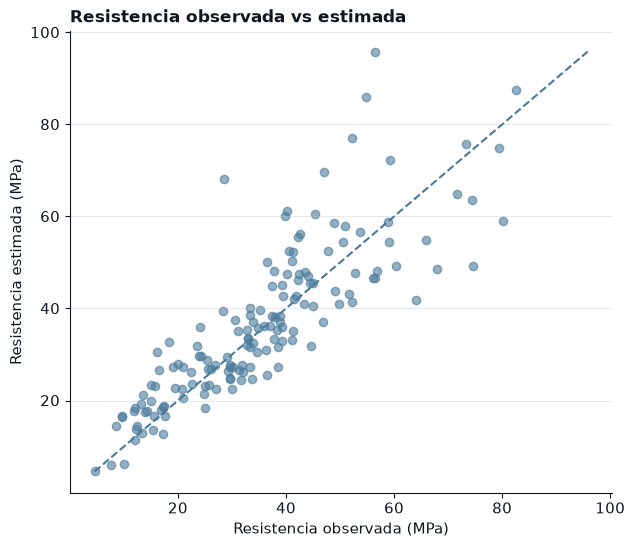

In [9]:
# Espacio de resolución — C8 · prueba final

# C8 - PREPARAR CONJUNTO DE PRUEBA
X_prueba = prueba[PREDICTORES].copy()
y_prueba = prueba[OBJETIVO].copy()

# 1. BASELINE EN PRUEBA
pred_baseline_prueba = baseline.predict(X_prueba)

rmse_baseline_prueba = np.sqrt(
    mean_squared_error(y_prueba, pred_baseline_prueba)
)

mae_baseline_prueba = mean_absolute_error(
    y_prueba,
    pred_baseline_prueba
)

neg_baseline = (pred_baseline_prueba < 0).sum()

# 2. MODELO LINEAL EN PRUEBA
pred_lineal_prueba = modelo_lineal.predict(X_prueba)

rmse_lineal_prueba = np.sqrt(
    mean_squared_error(y_prueba, pred_lineal_prueba)
)

mae_lineal_prueba = mean_absolute_error(
    y_prueba,
    pred_lineal_prueba
)

neg_lineal = (pred_lineal_prueba < 0).sum()

# 3. MODELO SELECCIONADO EN PRUEBA
pred_seleccionado_prueba = modelo_seleccionado.predict(X_prueba)

rmse_seleccionado_prueba = np.sqrt(
    mean_squared_error(y_prueba, pred_seleccionado_prueba)
)

mae_seleccionado_prueba = mean_absolute_error(
    y_prueba,
    pred_seleccionado_prueba
)

neg_seleccionado = (pred_seleccionado_prueba < 0).sum()

# 4. TABLA DE RESULTADOS EN PRUEBA
tabla_prueba = pd.DataFrame({
    "modelo": [
        "Baseline media",
        "Lineal",
        "Ridge grado 2 alpha=0.1"
    ],
    "RMSE_prueba": [
        rmse_baseline_prueba,
        rmse_lineal_prueba,
        rmse_seleccionado_prueba
    ],
    "MAE_prueba": [
        mae_baseline_prueba,
        mae_lineal_prueba,
        mae_seleccionado_prueba
    ],
    "predicciones_negativas": [
        neg_baseline,
        neg_lineal,
        neg_seleccionado
    ]
})

display(tabla_prueba.round(3))

# 5. REDUCCIÓN RELATIVA DEL RMSE VS LINEAL
reduccion_relativa = (
    (rmse_lineal_prueba - rmse_seleccionado_prueba)
    / rmse_lineal_prueba
) * 100

print(
    "Reducción relativa del RMSE respecto al lineal:",
    round(reduccion_relativa, 2),
    "%"
)

# 6. GRÁFICO OBSERVADO VS ESTIMADO
plt.figure(figsize=(7, 6))

plt.scatter(
    y_prueba,
    pred_seleccionado_prueba,
    alpha=0.6
)

limite_min = min(
    y_prueba.min(),
    pred_seleccionado_prueba.min()
)

limite_max = max(
    y_prueba.max(),
    pred_seleccionado_prueba.max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Resistencia observada (MPa)")
plt.ylabel("Resistencia estimada (MPa)")
plt.title("Resistencia observada vs estimada")

plt.show()

**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

En el conjunto de prueba, el modelo Ridge de grado 2 con alpha=0.1 siguió teniendo el menor error, con un RMSE de 9,566 MPa y un MAE de 6,756 MPa. Comparado con el modelo lineal, redujo el RMSE en un 8,5 %. No se obtuvieron predicciones negativas. En el gráfico se observa que la mayoría de las estimaciones siguen la tendencia de los valores reales, aunque existen algunos errores más grandes. Como se trabajó con una sola partición de prueba, no se puede asegurar que el mismo resultado se repita siempre.

## 8.3 Consigna C9 — Discrepancias entre métodos y edades

Seleccionar (a) el ensayo con mayor error absoluto del candidato y (b) el de mayor diferencia absoluta entre predicciones lineal y del candidato seleccionado. Si coinciden, usar el siguiente del segundo ordenamiento. Desempatar por menor `id_ensayo`. Si el seleccionado es lineal, las predicciones coinciden: mostrar los dos mayores errores absolutos e indicar que no hay discrepancia entre métodos; no evaluar una polinómica descartada. Mostrar ID, receta, ocho predictores, valor observado y ambas estimaciones. Comparar qué método se acerca más y proponer una hipótesis prudente, sin atribuir causalidad.

Calcular RMSE de lineal y candidato, número de ensayos y número de recetas por tres grupos fijados: **hasta 7 días, más de 7 hasta 28 días, y más de 28 días**. Las mismas recetas pueden aparecer en varios grupos de edad dentro de prueba; son un diagnóstico, no nuevas particiones independientes. No ajustar nuevamente por estos resultados.

In [10]:
# Espacio de resolución — C9 · errores y edades

# 1. TABLA CON RESULTADOS DE PRUEBA
diagnostico = prueba.copy()

diagnostico["pred_lineal"] = pred_lineal_prueba
diagnostico["pred_candidato"] = pred_seleccionado_prueba

diagnostico["error_abs_candidato"] = abs(
    diagnostico["resistencia_mpa"] - diagnostico["pred_candidato"]
)

diagnostico["diferencia_metodos"] = abs(
    diagnostico["pred_lineal"] - diagnostico["pred_candidato"]
)

# 2. ENSAYO CON MAYOR ERROR DEL MODELO SELECCIONADO
caso_mayor_error = diagnostico.sort_values(
    ["error_abs_candidato", "id_ensayo"],
    ascending=[False, True]
).iloc[0]

display(caso_mayor_error)

# 3. ENSAYO CON MAYOR DIFERENCIA ENTRE LINEAL Y RIDGE
orden_diferencias = diagnostico.sort_values(
    ["diferencia_metodos", "id_ensayo"],
    ascending=[False, True]
)

caso_mayor_diferencia = orden_diferencias.iloc[0]

# Si coincide con el caso anterior, usar el siguiente
if caso_mayor_diferencia["id_ensayo"] == caso_mayor_error["id_ensayo"]:
    caso_mayor_diferencia = orden_diferencias.iloc[1]

display(caso_mayor_diferencia)

# 4. CREAR GRUPOS DE EDAD
def grupo_edad(edad):
    if edad <= 7:
        return "Hasta 7 días"
    elif edad <= 28:
        return "Más de 7 hasta 28 días"
    else:
        return "Más de 28 días"

diagnostico["grupo_edad"] = diagnostico["edad_dias"].apply(grupo_edad)

# 5. RMSE POR GRUPO DE EDAD
resultados_edad = []

for grupo, datos in diagnostico.groupby("grupo_edad"):

    rmse_lineal = np.sqrt(
        mean_squared_error(
            datos["resistencia_mpa"],
            datos["pred_lineal"]
        )
    )

    rmse_candidato = np.sqrt(
        mean_squared_error(
            datos["resistencia_mpa"],
            datos["pred_candidato"]
        )
    )

    resultados_edad.append({
        "grupo_edad": grupo,
        "ensayos": len(datos),
        "recetas": datos["grupo_receta"].nunique(),
        "RMSE_lineal": rmse_lineal,
        "RMSE_candidato": rmse_candidato
    })

tabla_edades = pd.DataFrame(resultados_edad)

display(tabla_edades.round(3))

id_ensayo                86.000000
cemento                 379.500000
escoria                 151.200000
ceniza_volante            0.000000
agua                    153.900000
superplastificante       15.900000
agregado_grueso        1134.300000
agregado_fino           605.000000
edad_dias                 3.000000
resistencia_mpa          28.599464
grupo_receta            366.000000
pred_lineal              54.081715
pred_candidato           68.099175
error_abs_candidato      39.499710
diferencia_metodos       14.017460
Name: 14, dtype: float64

id_ensayo              611.000000
cemento                236.000000
escoria                  0.000000
ceniza_volante           0.000000
agua                   193.000000
superplastificante       0.000000
agregado_grueso        968.000000
agregado_fino          885.000000
edad_dias              365.000000
resistencia_mpa         25.083137
grupo_receta           178.000000
pred_lineal             58.162693
pred_candidato          23.205052
error_abs_candidato      1.878085
diferencia_metodos      34.957641
Name: 97, dtype: float64

,grupo_edad,ensayos,recetas,RMSE_lineal,RMSE_candidato
0,Hasta 7 días,35,25,11.849,10.092
1,Más de 28 días,45,22,13.231,11.318
2,Más de 7 hasta 28 días,73,63,7.340,7.999


**Interpretación.** Escribir entre tres y seis líneas que respondan la consigna a partir de las salidas.

El mayor error del modelo Ridge ocurrió en el ensayo 86, donde estimó una resistencia mucho mayor que la real y el modelo lineal quedó más cerca. En cambio, en el ensayo 611, donde ambos modelos dieron predicciones muy diferentes, Ridge fue el que mejor se acercó al valor observado. Al comparar por edades, Ridge tuvo menor RMSE en los ensayos de hasta 7 días y en los de más de 28 días, mientras que el modelo lineal fue ligeramente mejor entre más de 7 y 28 días. Esto muestra que el modelo seleccionado no es mejor en todos los casos y que su desempeño puede variar según la edad del ensayo.

# 9. Responder la pregunta y documentar la ejecución
## 9.1 Consigna C10 — Síntesis de 200–300 palabras

Responder si la polinómica regularizada mejora la estimación frente a lineal, usando evidencia de validación y prueba. Integrar dos observaciones del EDA, un error concreto, el diagnóstico por edades y dos límites. Distinguir desempeño predictivo, causalidad y seguridad estructural. Proponer una mejora futura que exigiría una nueva evaluación.

Antes de entregar: reiniciar el kernel, ejecutar de principio a fin, revisar las interpretaciones, conservar rutas relativas y registrar las fuentes consultadas. No se pide un informe separado.

**Respuesta.** Completar en este espacio.

La regresión polinómica regularizada con Ridge mejoró la estimación de la resistencia frente al modelo lineal. En validación, el modelo lineal obtuvo un RMSE de 10,019 MPa, mientras que Ridge de grado 2 con alpha=0.1 alcanzó 6,888 MPa. En prueba, la ventaja se mantuvo: el RMSE del lineal fue 10,455 MPa y el de Ridge 9,566 MPa, lo que representa una reducción aproximada del 8,5 %.
Durante el análisis exploratorio se observó que la resistencia aumenta en general con la edad, aunque existe una dispersión importante entre recetas diferentes. También se observó una relación positiva entre la cantidad de cemento y la resistencia, pero con bastante variabilidad, por lo que no puede interpretarse como una relación causal directa. Un caso concreto de error fue el ensayo 86, donde Ridge estimó 68,10 MPa frente a una resistencia real de 28,60 MPa.
El diagnóstico por edades mostró que Ridge tuvo menor RMSE en los ensayos de hasta 7 días y en los de más de 28 días, mientras que el modelo lineal fue ligeramente mejor entre más de 7 y 28 días.
Como limitaciones, estos resultados se obtuvieron a partir de una sola división de los datos en entrenamiento, validación y prueba, por lo que no se puede asegurar que el modelo tenga el mismo desempeño con otros conjuntos de datos. Además, el modelo permite hacer estimaciones, pero no demostrar que una variable sea la causa directa de un cambio en la resistencia. Tampoco puede usarse por sí solo para garantizar la seguridad de una estructura, ya que para eso también deben considerarse el diseño, las cargas, las dimensiones, la ejecución, etc
Como mejora futura, se podría evaluar el modelo con nuevos datos independientes y más variados, especialmente en rangos de edad y composición donde se observaron mayores errores.

## 9.2 Registrar versiones y archivos

El siguiente soporte informa versiones y disponibilidad de datos locales. Completar la entrega con respuestas y conclusiones verificadas.

In [11]:
print("Python:", sys.version.split()[0])
display(pd.Series({paquete:version(paquete) for paquete in ["numpy","pandas","matplotlib","scikit-learn"]},name="version").to_frame())
assert all((RUTA_DATOS/f"{nombre}.csv").is_file() for nombre in ["train","validacion","prueba"])
print("Datos locales disponibles. Revisar respuestas e interpretaciones antes de entregar.")

Python: 3.14.7


,version
numpy,2.5.2
pandas,3.0.5
matplotlib,3.11.1
scikit-learn,1.9.0


Datos locales disponibles. Revisar respuestas e interpretaciones antes de entregar.


**Interpretación.** Las versiones facilitan reproducir la ejecución. Ejecutar sin errores no sustituye resolver las consignas ni justificar las decisiones.

# Referencias

- Yeh, I. (1998). [Concrete Compressive Strength](https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength). UCI Machine Learning Repository. DOI: [10.24432/C5PK67](https://doi.org/10.24432/C5PK67). Datos bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); descarga y verificación: 18/9/2026.
- American Cement Association. [Cement & Concrete FAQ](https://www.cement.org/cement-concrete/cement-concrete-faq/). Lectura contextual seleccionada; consulta: 18/9/2026.
- Scikit-learn. Documentación de [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html) y [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html). Consulta: 18/9/2026.

La cátedra tradujo nombres y creó identificadores y particiones, sin modificar mediciones. La fuente no avala las conclusiones. La trazabilidad detallada está en `fuentes_licencias.md`.